# C01-GN — GMM trên RFM + AOV + Diversity (log1p + Standard + PCA 90%)

Thí nghiệm **C01-GN** (người chạy: Nguyên) theo chiến lược model. So với B01, **chỉ thêm 2 feature hành vi cấp khách**: **AOV** (giá trị trung bình mỗi đơn) và **Diversity** (số mã hàng khác nhau). Pipeline: làm sạch → 5 feature → `log1p` mọi biến → StandardScaler → PCA giữ ≥ 90% phương sai → GMM. Đây là nhánh chính của nhóm C; C02, C03, C04 so với kết quả này.

Cài đặt GMM, lưới `k × covariance_type` và quy tắc chọn giữ nguyên như B01-GN và thư mục GMM của Thuận để so sánh được. B01 được dựng lại ngay trong notebook để so cùng điều kiện. Mã "GN" được hiểu là GMM.

## Params

In [1]:
FEATURES_B01 = ["Recency", "Frequency", "Monetary"]
FEATURES = FEATURES_B01 + ["AOV", "Diversity"]      # C01: thêm AOV và Diversity
PCA_VAR = 0.90                    # giữ ít nhất 90% phương sai (giống B01)
RANDOM_STATE = 42                 # từ đây đến MIN_CLUSTER_FRAC: giống B01-GN / GMM của Thuận
N_INIT = 10
MAX_ITER = 300
TOL = 1e-3
REG_COVAR = 1e-6
INIT_PARAMS = "kmeans"
K_RANGE = range(2, 11)
COV_TYPES = ["full", "tied", "diag", "spherical"]
MIN_CLUSTER_FRAC = 0.01           # điều kiện chọn: mỗi cụm >= 1% số khách

## Import thư viện và đọc dữ liệu

In [2]:
from pathlib import Path
import json
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=UserWarning)

def find(rel):
    # Tự tìm file trong repo, không phụ thuộc nơi mở notebook
    return next(c for p in [Path.cwd(), *Path.cwd().parents]
                for c in (p / rel, p / "project" / rel) if c.exists())

# Dùng chung file đặc trưng của nhóm (cùng nguồn với A01..B04), không sao chép thêm
DATA = find("notebooks/02_baseline_kmeans/12-11-2026-hieu-kmeans/data/customer_features.csv")
FIG, OUT = Path("figures"), Path("data")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

# AOV = avg_order_value, Diversity = n_stock_codes (số mã hàng khác nhau của khách)
df = pd.read_csv(DATA, dtype={"CustomerID": "string"}).rename(columns={"avg_order_value": "AOV", "n_stock_codes": "Diversity"})
X = df[FEATURES].astype(float)
assert df["CustomerID"].is_unique and X.notna().all().all() and (X >= 0).all().all()   # log1p cần X >= 0
assert np.allclose(df["AOV"], df["Monetary"] / df["Frequency"], atol=0.01)              # AOV = Monetary / Frequency
print("Dữ liệu đầu vào:", X.shape)
X.describe().round(2)

Dữ liệu đầu vào: (4327, 5)


,Recency,Frequency,Monetary,AOV,Diversity
count,4327.00,4327.00,4327.00,4327.00,4327.00
mean,93.04,4.25,1944.95,372.40,61.49
std,99.98,7.64,8441.89,466.49,85.31
min,1.00,1.00,2.90,2.90,1.00
25%,18.00,1.00,301.52,175.47,16.00
50%,51.00,2.00,657.90,286.70,35.00
75%,143.00,5.00,1624.10,421.99,77.00
max,374.00,206.00,278748.02,14844.77,1784.00


**Nhận xét:** 4.327 khách, 5 feature, không thiếu giá trị, không có giá trị âm (điều kiện để dùng `log1p`). AOV đúng bằng Monetary / Frequency (đã kiểm). Diversity có median 35 mã hàng nhưng max 1.784. Đây là file làm sạch cũ của nhóm, không phải feature tính thẳng từ raw (chi tiết ở A02-KM); các thí nghiệm cùng dùng file này nên so sánh được với nhau.

## Biến đổi `log1p` và mức độc lập của AOV

Kiểm tra độ lệch (skew) trước và sau `log1p`. Vì AOV = Monetary / Frequency, đo luôn phần của `log1p(AOV)` mà `log1p(Frequency)` và `log1p(Monetary)` đã giải thích (R² của hồi quy tuyến tính).

In [3]:
skew = pd.DataFrame({"skew_raw": X.skew(), "skew_log1p": np.log1p(X).skew()}).round(2)

L = np.log1p(X)
A = np.c_[np.ones(len(L)), L["Frequency"], L["Monetary"]]
beta = np.linalg.lstsq(A, L["AOV"], rcond=None)[0]
r2 = 1 - ((L["AOV"] - A @ beta) ** 2).sum() / ((L["AOV"] - L["AOV"].mean()) ** 2).sum()
print(f"R² của log1p(AOV) theo log1p(Frequency) và log1p(Monetary): {r2:.4f}")
skew

R² của log1p(AOV) theo log1p(Frequency) và log1p(Monetary): 0.9832


,skew_raw,skew_log1p
Recency,1.25,-0.33
Frequency,11.95,1.21
Monetary,21.04,0.35
AOV,11.94,-0.00
Diversity,6.92,-0.24


**Nhận xét:** `log1p` kéo AOV từ lệch phải rất mạnh (11,94) về đối xứng (0,00) và Diversity từ 6,92 về −0,24; Recency, Frequency, Monetary như ở B01. Quan trọng hơn, **`log1p(AOV)` được Frequency và Monetary giải thích tới 98,32%** (R² = 0,9832): AOV vốn là Monetary chia Frequency nên phần thông tin độc lập của nó rất nhỏ. Hệ quả này xuất hiện ngay ở bước PCA bên dưới.

## Chuẩn hóa và PCA giữ 90% phương sai

In [4]:
X_scaled = Pipeline([("log1p", FunctionTransformer(np.log1p)),
                     ("scaler", StandardScaler())]).fit_transform(X)

ev = PCA(svd_solver="full").fit(X_scaled).explained_variance_ratio_
cum = np.cumsum(ev)
n_pc = int(np.searchsorted(cum, PCA_VAR) + 1)
pca = PCA(n_components=n_pc, svd_solver="full").fit(X_scaled)
Z = pca.transform(X_scaled)

print("Phương sai từng PC:", ev.round(4))
print("Phương sai tích lũy:", cum.round(4))
print(f"Số PC giữ lại: {n_pc} / {len(FEATURES)} (phương sai giữ {cum[n_pc-1]:.2%})")
pd.DataFrame(pca.components_, index=[f"PC{i+1}" for i in range(n_pc)], columns=FEATURES).round(3)

Phương sai từng PC: [6.233e-01 2.024e-01 9.820e-02 7.540e-02 6.000e-04]
Phương sai tích lũy: [0.6233 0.8257 0.924  0.9994 1.    ]
Số PC giữ lại: 3 / 5 (phương sai giữ 92.40%)


,Recency,Frequency,Monetary,AOV,Diversity
PC1,-0.375,0.476,0.542,0.342,0.472
PC2,0.522,-0.361,0.181,0.751,0.028
PC3,0.757,0.417,0.087,-0.359,0.341


**Nhận xét:** Cần **3 PC** để vượt 90% (PC1 62,33%, PC2 20,24%, PC3 9,82%, cộng lại 92,40%), tức PCA giảm 5 biến xuống 3 chiều. PC1 là trục "mức độ hoạt động và chi tiêu" (Frequency, Monetary, Diversity, AOV cùng dương, Recency âm); PC2 chủ yếu là AOV (0,75) và Recency (0,52); PC3 chủ yếu là Recency (0,76) và Frequency (0,42). PC5 chỉ giữ **0,06%** phương sai: đó chính là hướng phụ thuộc tuyến tính của AOV vào Frequency và Monetary, được loại bỏ khi cắt ở 3 PC.

## Chọn số thành phần k và loại hiệp phương sai

Chỉ số chính là **BIC** (thấp hơn là tốt hơn). Silhouette, DBI, CHI tính trên `Z` chỉ để tham khảo vì GMM là mô hình xác suất, các cụm có thể chồng lấn. Quét `k = 2..10` × 4 loại `covariance_type`.

In [5]:
def fit_gmm(Zs, k, cov):
    return GaussianMixture(n_components=int(k), covariance_type=cov, n_init=N_INIT, max_iter=MAX_ITER, tol=TOL,
                           reg_covar=REG_COVAR, init_params=INIT_PARAMS, random_state=RANDOM_STATE).fit(Zs)

def sweep(Zs):
    rows = []
    for cov in COV_TYPES:
        for k in K_RANGE:
            gm = fit_gmm(Zs, k, cov)
            lab = gm.predict(Zs); sizes = np.bincount(lab, minlength=k)
            ok = len(np.unique(lab)) > 1
            rows.append({"covariance_type": cov, "k": k, "BIC": gm.bic(Zs), "AIC": gm.aic(Zs),
                         "Silhouette": silhouette_score(Zs, lab) if ok else np.nan,
                         "DBI": davies_bouldin_score(Zs, lab) if ok else np.nan,
                         "CHI": calinski_harabasz_score(Zs, lab) if ok else np.nan,
                         "min_cluster": int(sizes.min()), "converged": bool(gm.converged_)})
    return pd.DataFrame(rows)

def select(res, n):
    # BIC thấp nhất trong các cấu hình đã hội tụ và có mọi cụm >= 1% số khách
    ok = res[res["converged"] & (res["min_cluster"] >= MIN_CLUSTER_FRAC * n)]
    return ok.loc[ok["BIC"].idxmin()]

res = sweep(Z)
best = select(res, len(X))
print(f"Chọn: {best['covariance_type']}, k={int(best['k'])}, BIC={best['BIC']:,.1f}, "
      f"Silhouette={best['Silhouette']:.4f}, cụm nhỏ nhất={int(best['min_cluster'])}")
print("k được chọn có chạm biên của lưới (k = 10) không:", int(best["k"]) == max(K_RANGE))
res.loc[res.groupby("covariance_type")["BIC"].idxmin()].round(4).reset_index(drop=True)

Chọn: full, k=6, BIC=36,807.8, Silhouette=0.0954, cụm nhỏ nhất=119
k được chọn có chạm biên của lưới (k = 10) không: False


,covariance_type,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
0,diag,10,37665.7456,37226.0341,0.2106,1.1892,1501.2517,45,True
1,full,6,36807.8110,36431.8258,0.0954,1.9924,895.0930,119,True
2,spherical,10,37756.4392,37444.1803,0.2173,1.1928,1525.9039,51,True
3,tied,10,37788.8867,37502.1184,0.1925,1.2567,1201.5268,17,True


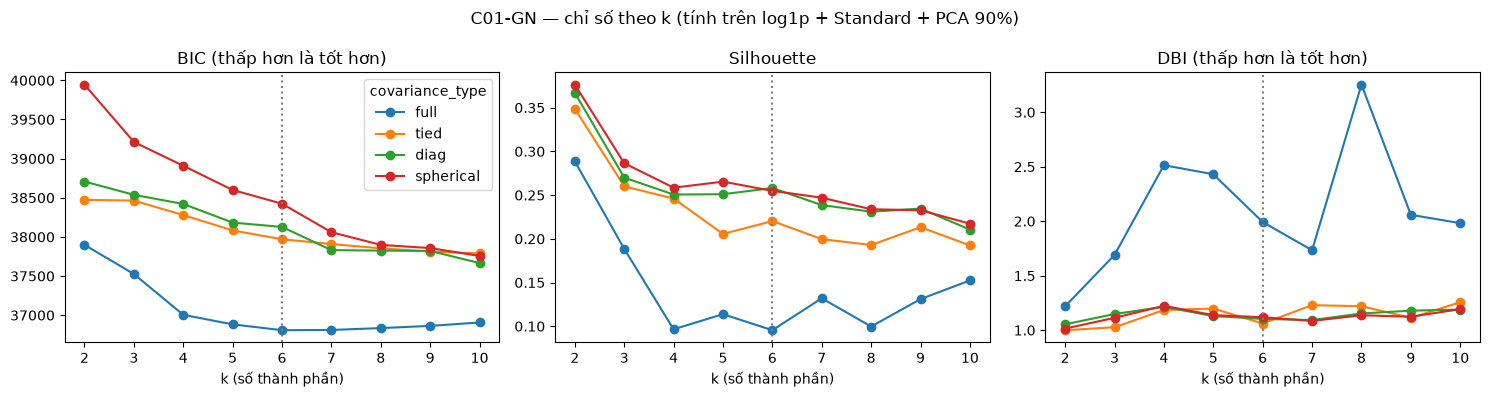

Silhouette cao nhất: {'covariance_type': 'spherical', 'k': 2, 'Silhouette': 0.3764138436941794, 'min_cluster': 1798}


,k,BIC,AIC,Silhouette,DBI,CHI,min_cluster,converged
0,2,37898.2706,37777.1907,0.2887,1.2187,2076.1053,1750,True
1,3,37526.0491,37341.2429,0.1886,1.6906,1714.5306,1035,True
2,4,37004.3629,36755.8304,0.0965,2.5141,891.6366,477,True
3,5,36882.7480,36570.4891,0.1138,2.4309,937.4270,564,True
4,6,36807.8110,36431.8258,0.0954,1.9924,895.0930,119,True
5,7,36810.9883,36371.2768,0.1320,1.7337,1031.1983,178,True
6,8,36835.1254,36331.6876,0.0997,3.2537,641.1872,51,True
7,9,36862.9270,36295.7629,0.1310,2.0587,948.0310,107,True
8,10,36906.8244,36275.9340,0.1524,1.9822,963.0976,69,True


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["BIC", "Silhouette", "DBI"]):
    for cov in COV_TYPES:
        s = res[res["covariance_type"] == cov]
        ax.plot(s["k"], s[col], marker="o", label=cov)
    ax.axvline(int(best["k"]), color="gray", ls=":")
    ax.set_xlabel("k (số thành phần)"); ax.set_title(col + (" (thấp hơn là tốt hơn)" if col in ("BIC", "DBI") else ""))
axes[0].legend(title="covariance_type")
plt.suptitle("C01-GN — chỉ số theo k (tính trên log1p + Standard + PCA 90%)")
plt.tight_layout(); fig.savefig(FIG / "gmm_metrics.png", dpi=150, bbox_inches="tight"); plt.show()

print("Silhouette cao nhất:", res.loc[res["Silhouette"].idxmax(), ["covariance_type", "k", "Silhouette", "min_cluster"]].to_dict())
res[res["covariance_type"] == best["covariance_type"]].drop(columns="covariance_type").round(4)

**Nhận xét:** BIC thấp nhất ở **`full`, k = 6** (36.807,8), cụm nhỏ nhất 119 khách. BIC của `full` giảm từ k = 2 (37.898,3) đến k = 6 rồi gần như đi ngang: k = 7 chỉ cao hơn 3,2 điểm (36.811,0), nên **k = 6 và k = 7 gần như hòa** và việc chọn k = 6 mong manh. `diag`, `tied`, `spherical` đều có BIC thấp nhất ở biên k = 10 nhưng vẫn cao hơn `full` k = 6 (37.666 / 37.789 / 37.756). Silhouette của cấu hình được chọn chỉ 0,0954: các cụm chồng lấn nhiều.

## Train mô hình cuối

In [7]:
model = Pipeline([("log1p", FunctionTransformer(np.log1p)), ("scaler", StandardScaler()),
                  ("pca", PCA(n_components=n_pc, svd_solver="full")),
                  ("gmm", GaussianMixture(n_components=int(best["k"]), covariance_type=best["covariance_type"],
                                          n_init=N_INIT, max_iter=MAX_ITER, tol=TOL, reg_covar=REG_COVAR,
                                          init_params=INIT_PARAMS, random_state=RANDOM_STATE))]).fit(X)
gm = model["gmm"]
assert np.allclose(model[:-1].transform(X), Z)                       # pipeline cho đúng không gian đã quét
labels, proba = gm.predict(Z), gm.predict_proba(Z)
assert (labels == fit_gmm(Z, best["k"], best["covariance_type"]).predict(Z)).all()

print("Số khách theo cụm:", np.bincount(labels).tolist())
print("Hội tụ:", gm.converged_, "| số vòng EM:", gm.n_iter_, "| BIC:", round(gm.bic(Z), 1))
print("Silhouette:", round(silhouette_score(Z, labels), 4), "| DBI:", round(davies_bouldin_score(Z, labels), 4),
      "| CHI:", round(calinski_harabasz_score(Z, labels), 1))
soft = int((proba.max(axis=1) < 0.8).sum())
print(f"Khách có xác suất cụm cao nhất < 0,8: {soft} ({soft / len(X):.1%})")

Số khách theo cụm: [648, 1638, 609, 119, 657, 656]
Hội tụ: True | số vòng EM: 33 | BIC: 36807.8


Silhouette: 0.0954 | DBI: 1.9924 | CHI: 895.1
Khách có xác suất cụm cao nhất < 0,8: 3016 (69.7%)


**Nhận xét:** 6 cụm, cỡ từ 119 đến 1.638 khách, hội tụ sau 33 vòng EM; Silhouette 0,0954, DBI 1,9924. Ranh giới giữa các cụm **rất mờ**: 3.016 khách (69,7%) có xác suất cụm cao nhất dưới 0,8, nên đây là phân khúc "mềm", chồng lấn nhiều hơn hẳn B01.

## Hồ sơ cụm

Mô tả bằng trung vị **trên thang gốc** (không phải log). `Monetary_share_pct` là tỷ trọng tổng Monetary của cụm.

In [8]:
prof = X.assign(cluster=labels, max_proba=proba.max(axis=1)).groupby("cluster").agg(
    customers=("Monetary", "size"),
    Recency=("Recency", "median"),
    Frequency=("Frequency", "median"),
    Monetary=("Monetary", "median"),
    AOV=("AOV", "median"),
    Diversity=("Diversity", "median"),
    Monetary_sum=("Monetary", "sum"),
    max_proba_mean=("max_proba", "mean"))
prof["customer_share_pct"] = (100 * prof["customers"] / len(X)).round(2)
prof["Monetary_share_pct"] = (100 * prof["Monetary_sum"] / prof["Monetary_sum"].sum()).round(2)
prof = prof.drop(columns="Monetary_sum")
prof.round(2)

,customers,Recency,Frequency,Monetary,AOV,Diversity,max_proba_mean,customer_share_pct,Monetary_share_pct
cluster,,,,,,,,,
0,648,23.0,2.0,288.02,171.80,20.0,0.63,14.98,3.56
1,1638,23.0,5.0,1537.32,307.36,78.0,0.69,37.86,43.53
2,609,93.0,2.0,756.82,415.38,36.0,0.56,14.07,10.38
3,119,5.0,19.0,12353.29,872.07,166.0,0.72,2.75,36.80
4,657,100.0,1.0,307.53,305.78,17.0,0.70,15.18,2.82
5,656,257.0,1.0,249.52,189.87,16.0,0.73,15.16,2.91


**Nhận xét** (tên nhóm chỉ là cách gọi gợi ý từ trung vị, chưa phải kết luận của mô hình):
- Cụm 3 (119 khách, 2,8%): Recency 5, Frequency 19, Monetary ≈ 12.353, AOV ≈ 872, Diversity 166 → **nhóm VIP nhỏ**; chiếm 36,8% tổng Monetary.
- Cụm 1 (1.638 khách, 37,9%): Recency 23, Frequency 5, Monetary ≈ 1.537, AOV ≈ 307, Diversity 78 → **khách khá thường xuyên, còn gần**; 43,5% Monetary.
- Cụm 0 (648 khách, 15,0%): Recency 23, Frequency 2, Monetary ≈ 288, AOV ≈ 172, Diversity 20 → **mua ít, gần đây, giỏ nhỏ**.
- Cụm 2 (609 khách, 14,1%): Recency 93, Frequency 2, Monetary ≈ 757, AOV ≈ 415, Diversity 36 → **mua ít lần nhưng giỏ lớn, đã khá lâu**.
- Cụm 4 (657 khách, 15,2%): Recency 100, Frequency 1, Monetary ≈ 308, AOV ≈ 306, Diversity 17 → **mua một lần, khá lâu**.
- Cụm 5 (656 khách, 15,2%): Recency 257, Frequency 1, Monetary ≈ 250, AOV ≈ 190, Diversity 16 → **mua một lần, rất lâu chưa quay lại**.

AOV và Diversity giúp phân biệt thêm giữa các nhóm cùng Frequency thấp (cụm 0, 2, 4, 5 khác nhau rõ ở AOV: 172 / 415 / 306 / 190).

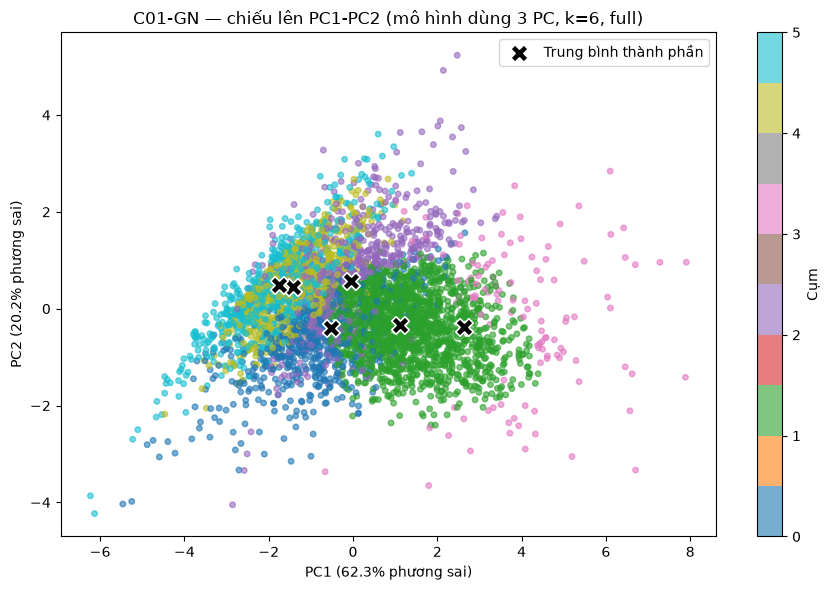

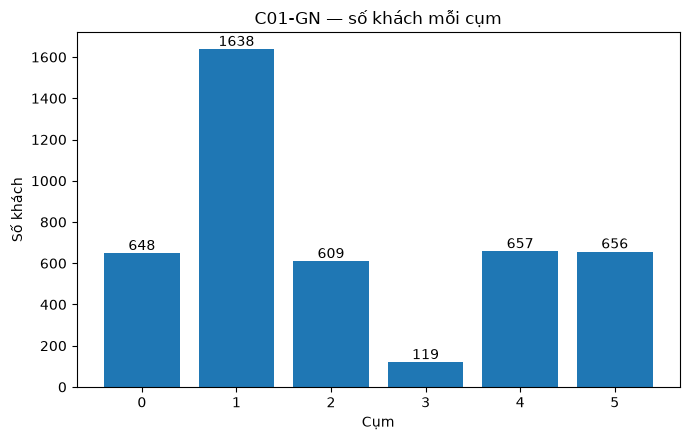

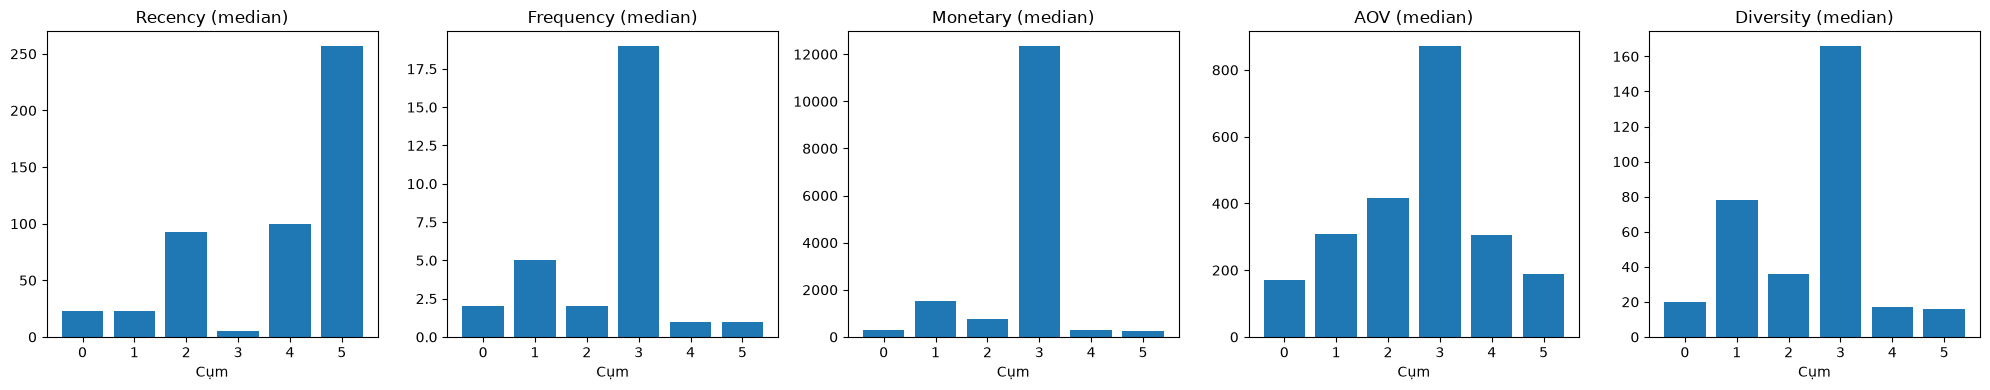

In [9]:
# Hình 1: PC1-PC2 (không gian mô hình có 3 PC; hình chiếu lên 2 trục đầu)
centers = gm.means_
fig, ax = plt.subplots(figsize=(9, 6))
sc = ax.scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=16, alpha=0.6, rasterized=True)
ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="X", s=160, edgecolors="white", linewidths=1.2,
           label="Trung bình thành phần")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} phương sai)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} phương sai)")
ax.set_title(f"C01-GN — chiếu lên PC1-PC2 (mô hình dùng {n_pc} PC, k={gm.n_components}, {gm.covariance_type})")
ax.legend(loc="best"); fig.colorbar(sc, ax=ax, label="Cụm", ticks=sorted(np.unique(labels)))
fig.tight_layout(); fig.savefig(FIG / "gmm_clusters_pca.png", dpi=150, bbox_inches="tight"); plt.show()

# Hình 2: số khách mỗi cụm
cnt = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(cnt.index.astype(str), cnt.values); ax.bar_label(bars)
ax.set_xlabel("Cụm"); ax.set_ylabel("Số khách"); ax.set_title("C01-GN — số khách mỗi cụm")
plt.tight_layout(); fig.savefig(FIG / "gmm_cluster_distribution.png", dpi=150); plt.show()

# Hình 3: trung vị 5 feature từng cụm (thang gốc)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, f in zip(axes, FEATURES):
    ax.bar(prof.index.astype(str), prof[f]); ax.set_title(f + " (median)"); ax.set_xlabel("Cụm")
plt.tight_layout(); fig.savefig(FIG / "gmm_feature_comparison.png", dpi=150); plt.show()

**Nhận xét:** Trên mặt phẳng PC1-PC2 các cụm nằm đè lên nhau, khớp với 69,7% khách có xác suất cụm < 0,8. Biểu đồ trung vị cho thấy cụm 3 nổi bật ở mọi biến "giá trị" (Frequency, Monetary, AOV, Diversity) và cụm 5 ở Recency; bốn cụm còn lại phân biệt chủ yếu nhờ Recency, Frequency và AOV.

## Đối chiếu B01 (dựng lại cùng điều kiện)

Dựng lại B01 (chỉ RFM: `log1p` → Standard → PCA 90% → GMM, cùng lưới và quy tắc) và kiểm tra nó khớp thư mục B01-GN đã có. Vì hai thí nghiệm nằm trên hai không gian khác nhau (3 biến / 2 PC và 5 biến / 3 PC), BIC và Silhouette không so trực tiếp được; ngoài giá trị trên không gian riêng, bảng còn tính Silhouette của mỗi cách chia trên **cả hai không gian**.

In [10]:
Xb = StandardScaler().fit_transform(np.log1p(X[FEATURES_B01]))
cum_b = np.cumsum(PCA(svd_solver="full").fit(Xb).explained_variance_ratio_)
n_pc_b = int(np.searchsorted(cum_b, PCA_VAR) + 1)
Z_b01 = PCA(n_components=n_pc_b, svd_solver="full").fit_transform(Xb)
res_b01 = sweep(Z_b01)
best_b01 = select(res_b01, len(X))
gm_b01 = fit_gmm(Z_b01, best_b01["k"], best_b01["covariance_type"])
labels_b01 = gm_b01.predict(Z_b01)

# Kiểm tra khớp B01-GN đã làm
ref = json.load(open(find("notebooks/03_clustering_eval/17-11-2026-Nguyen-gmm-b01/gmm_params.json"), encoding="utf8"))
print(f"B01 dựng lại: {n_pc_b}/3 PC | {best_b01['covariance_type']}, k={int(best_b01['k'])}, BIC={best_b01['BIC']:,.1f}")
print(f"B01-GN đã lưu: {ref['n_components']} PC | {ref['covariance_type']}, k={ref['k']}, BIC={ref['bic']:,.1f}")
print("Khớp:", n_pc_b == ref["n_components"] and best_b01["covariance_type"] == ref["covariance_type"]
      and int(best_b01["k"]) == ref["k"] and round(best_b01["BIC"], 1) == round(ref["bic"], 1))

B01 dựng lại: 2/3 PC | full, k=4, BIC=24,347.1
B01-GN đã lưu: 2 PC | full, k=4, BIC=24,347.1
Khớp: True


In [11]:
def line(name, n_feat, n_components, gm_, Zs, lab):
    return {"Thí nghiệm": name, "Số biến": n_feat, "Số PC": n_components, "covariance": gm_.covariance_type,
            "k": gm_.n_components, "BIC": round(gm_.bic(Zs), 1),
            "Silhouette": round(silhouette_score(Zs, lab), 4), "DBI": round(davies_bouldin_score(Zs, lab), 4),
            "CHI": round(calinski_harabasz_score(Zs, lab), 1),
            "Khách xác suất < 0,8 (%)": round(100 * (gm_.predict_proba(Zs).max(axis=1) < 0.8).mean(), 1),
            "Kích thước cụm": sorted(np.bincount(lab).tolist(), reverse=True),
            "Silhouette trên không gian B01": round(silhouette_score(Z_b01, lab), 4),
            "Silhouette trên không gian C01": round(silhouette_score(Z, lab), 4)}

cmp = pd.DataFrame([line("B01-GN (dựng lại)", len(FEATURES_B01), n_pc_b, gm_b01, Z_b01, labels_b01),
                    line("C01-GN", len(FEATURES), n_pc, gm, Z, labels)])
ari = adjusted_rand_score(labels_b01, labels)
print("ARI giữa cách chia B01 và C01:", round(ari, 4))
print("\nBảng chéo (hàng: cụm B01, cột: cụm C01):")
print(pd.crosstab(pd.Series(labels_b01, name="B01"), pd.Series(labels, name="C01")).to_string())
cmp

ARI giữa cách chia B01 và C01: 0.3232

Bảng chéo (hàng: cụm B01, cột: cụm C01):
C01    0    1    2    3    4    5
B01                              
0    418   93  128    2  358   22
1    164  567    0  106    1    0
2      1    5   59    0  275  619
3     65  973  422   11   23   15


,Thí nghiệm,Số biến,Số PC,covariance,k,BIC,Silhouette,DBI,CHI,"Khách xác suất < 0,8 (%)",Kích thước cụm,Silhouette trên không gian B01,Silhouette trên không gian C01
0,B01-GN (dựng lại),3,2,full,4,24347.1,0.3082,1.0652,2747.6,45.6,"[1509, 1021, 959, 838]",0.3082,0.1673
1,C01-GN,5,3,full,6,36807.8,0.0954,1.9924,895.1,69.7,"[1638, 657, 656, 648, 609, 119]",0.0572,0.0954


**Nhận xét:**
- **Dựng lại B01 khớp B01-GN** (cùng `full`, k = 4, BIC 24.347,1), nên phép đối chiếu đáng tin.
- **Thêm AOV và Diversity làm GMM chia mịn hơn nhưng yếu hơn về độ tách:** BIC chọn k = 6 thay vì 4; Silhouette trên không gian riêng giảm từ 0,3082 xuống 0,0954; khách có xác suất cụm < 0,8 tăng từ 45,6% lên 69,7%. Các số này tính trên hai không gian khác nhau nên chỉ để tham khảo.
- **So trên cùng không gian, phép chia của C01 không gọn hơn:** trên không gian B01 (chỉ RFM), Silhouette của phép chia B01 là 0,3082 so với 0,0572 của C01; ngay trên không gian C01, phép chia B01 vẫn cao hơn (0,1673 so với 0,0954). Tức GMM chọn theo BIC tạo cụm chồng lấn, không phải cụm chặt hơn.
- **Hai cách chia khác nhau nhiều (ARI 0,3232), nhưng có quan hệ lồng nhau:** nhóm "khá thường xuyên" của B01 (cụm 3, 1.509 khách) tách thành cụm 1 (973 khách) và cụm 2 (422 khách) của C01 theo mức giỏ hàng; nhóm "lâu chưa quay lại" của B01 (cụm 2, 959 khách) tách thành cụm 5 (619 khách, Recency 257) và cụm 4 (275 khách, Recency 100); một nhóm VIP nhỏ 119 khách xuất hiện lại (cụm 3), điều B01 không có.
- **AOV gần như thừa về thông tin** (R² = 0,9832 với Frequency và Monetary), nên khác biệt so với B01 đến từ Diversity và/hoặc phần dư nhỏ của AOV; thí nghiệm này thêm hai biến cùng lúc nên chưa tách riêng được tác động của từng biến (cần chạy riêng từng biến, không nằm trong bảng chiến lược).

## Lưu kết quả

In [12]:
pd.DataFrame({"CustomerID": df["CustomerID"], "cluster": labels, "max_proba": proba.max(axis=1).round(4)}) \
    .to_csv(OUT / "gmm_c01_labels.csv", index=False)
joblib.dump(model, "gmm_model.pkl")

params = {"experiment": "C01-GN", "features": FEATURES, "feature_sources": {"AOV": "avg_order_value", "Diversity": "n_stock_codes"},
          "transform": "log1p", "scaler": "StandardScaler",
          "pca_variance": PCA_VAR, "n_components": n_pc, "pca_variance_kept": float(cum[n_pc - 1]),
          "covariance_type": best["covariance_type"], "k": int(best["k"]),
          "bic": float(best["BIC"]), "aic": float(best["AIC"]), "silhouette": float(best["Silhouette"]),
          "dbi": float(best["DBI"]), "chi": float(best["CHI"]), "min_cluster": int(best["min_cluster"]),
          "converged": bool(gm.converged_), "n_iter": int(gm.n_iter_), "r2_logAOV_on_logF_logM": round(float(r2), 4),
          "gmm_params": gm.get_params()}
json.dump(params, open("gmm_params.json", "w", encoding="utf8"), ensure_ascii=False, indent=2)
print("Đã lưu:", sorted(p.name for p in Path(".").iterdir() if p.is_file()), sorted(p.name for p in OUT.iterdir()))

Đã lưu: ['Working_details_GMM_C01.xlsx', 'gmm_c01.ipynb', 'gmm_model.pkl', 'gmm_params.json'] ['gmm_c01_labels.csv']


## Working_details

Ghi bảng tóm tắt theo bố cục `Working_details_GMM_RFM.xlsx` của Thuận (và B01-GN): sheet chính (thiết lập, bảng quét `covariance_type × k`, bảng cụm) và sheet `So_sanh_cau_hinh`.

In [13]:
from openpyxl import Workbook
from openpyxl.styles import Font

wb = Workbook(); ws = wb.active; ws.title = "GMM_C01"
B = Font(name="Calibri", bold=True)
def put(sheet, cell, value, bold=False, fmt=None):
    sheet[cell] = value
    sheet[cell].font = B if bold else Font(name="Calibri")
    if fmt: sheet[cell].number_format = fmt

n = len(X)
put(ws, "A1", "THÍ NGHIỆM GMM — C01 (RFM + AOV + Diversity, log1p, Standard, PCA 90%)", bold=True)
put(ws, "A2", "Trạng thái", bold=True)
put(ws, "B2", "Đã chạy xong; BIC/AIC/Silhouette/DBI/CHI tính trên Z (không gian log1p + Standard + PCA 90%)")
for c, v in zip("ABDE", ["Thiết lập", "Giá trị", "Tham số khác", "Giá trị"]): put(ws, f"{c}4", v, bold=True)
left = [("Feature", "Recency, Frequency, Monetary, AOV, Diversity"),
        ("Dữ liệu train", f"Z (log1p → Standard → PCA 90%, {n_pc} PC)"),
        ("Nguồn dữ liệu", "12-11-2026-hieu-kmeans/data/customer_features.csv"),
        ("covariance_type", best["covariance_type"]), ("k được chọn", int(best["k"])),
        ("random_state", RANDOM_STATE), ("n_init", N_INIT), ("init_params", INIT_PARAMS)]
right = [("max_iter", MAX_ITER), ("tol", TOL), ("reg_covar", REG_COVAR), ("Tổng khách hàng", int(n)),
         ("Số vòng EM", int(gm.n_iter_)), ("Hội tụ", bool(gm.converged_)),
         ("Quy tắc chọn", "BIC thấp nhất, mỗi cụm >= 1% số khách"),
         ("PCA", f"{n_pc}/{len(FEATURES)} PC, phương sai {cum[n_pc-1]:.2%}")]
for i, ((a, b), (d, e)) in enumerate(zip(left, right), start=5):
    put(ws, f"A{i}", a); put(ws, f"B{i}", b); put(ws, f"D{i}", d); put(ws, f"E{i}", e)

hdr = ["covariance_type", "k", "BIC", "AIC", "Silhouette", "DBI", "CHI", "Cụm nhỏ nhất", "Nhận xét"]
for c, v in zip("ABCDEFGHI", hdr): put(ws, f"{c}14", v, bold=True)
for i, r in enumerate(res.itertuples(), start=15):
    if r.covariance_type == best["covariance_type"] and r.k == int(best["k"]): note = "được chọn"
    elif not r.converged: note = "không hội tụ"
    elif r.min_cluster < MIN_CLUSTER_FRAC * n: note = "loại: cụm nhỏ nhất < 1% số khách"
    else: note = ""
    vals = [r.covariance_type, int(r.k), round(r.BIC, 2), round(r.AIC, 2), round(r.Silhouette, 4), round(r.DBI, 4),
            round(r.CHI, 2), int(r.min_cluster), note]
    fmts = [None, None, "0.00", "0.00", "0.0000", "0.0000", "0.00", None, None]
    for c, v, f in zip("ABCDEFGHI", vals, fmts): put(ws, f"{c}{i}", v, fmt=f)

r0 = 15 + len(res) + 1
for c, v in zip("ABCDEFGHIJ", ["Cụm", "Mô tả (so với trung vị chung)", "Số khách", "Tỷ lệ (%)", "Recency (median)",
                                "Frequency (median)", "Monetary (median)", "AOV (median)", "Diversity (median)",
                                "Tỷ trọng Monetary (%)"]):
    put(ws, f"{c}{r0}", v, bold=True)
med = X.median()
def mo_ta(p):
    return ("Recency xa (lâu chưa mua)" if p["Recency"] > med["Recency"] else "Recency gần") + ", " + \
           ("Frequency cao" if p["Frequency"] > med["Frequency"] else "Frequency thấp") + ", " + \
           ("Monetary cao" if p["Monetary"] > med["Monetary"] else "Monetary thấp")
for j, (cl, p) in enumerate(prof.iterrows(), start=r0 + 1):
    put(ws, f"A{j}", int(cl)); put(ws, f"B{j}", mo_ta(p)); put(ws, f"C{j}", int(p["customers"]))
    put(ws, f"D{j}", float(p["customer_share_pct"]), fmt="0.00"); put(ws, f"E{j}", float(p["Recency"]))
    put(ws, f"F{j}", float(p["Frequency"])); put(ws, f"G{j}", float(p["Monetary"]), fmt="0.00")
    put(ws, f"H{j}", float(p["AOV"]), fmt="0.00"); put(ws, f"I{j}", float(p["Diversity"]))
    put(ws, f"J{j}", float(p["Monetary_share_pct"]), fmt="0.00")
for col, w in zip("ABCDEFGHIJ", [16, 22, 17, 19, 20, 21, 25, 22, 18, 22]): ws.column_dimensions[col].width = w
ws.freeze_panes = "A5"

ws2 = wb.create_sheet("So_sanh_cau_hinh")
cols2 = ["Thí nghiệm", "Số biến", "Số PC", "covariance", "k", "BIC", "Silhouette", "DBI", "CHI",
         "Khách xác suất < 0,8 (%)", "Silhouette trên không gian B01", "Silhouette trên không gian C01", "Kích thước cụm"]
letters = "ABCDEFGHIJKLM"
for c, v in zip(letters, cols2): put(ws2, f"{c}1", v, bold=True)
for i, r in enumerate(cmp.itertuples(index=False), start=2):
    vals = [r[0], int(r[1]), int(r[2]), r[3], int(r[4]), float(r[5]), float(r[6]), float(r[7]), float(r[8]),
            float(r[9]), float(r[11]), float(r[12]), str(r[10])]
    for c, v in zip(letters, vals): put(ws2, f"{c}{i}", v)
put(ws2, "A5", "BIC và Silhouette tính trên không gian khác nhau của từng dòng nên không so trực tiếp; hai cột Silhouette 'trên không gian' là phép so cùng không gian.")
put(ws2, "A6", f"ARI giữa cách chia B01 (dựng lại) và C01: {ari:.4f}")
put(ws2, "A7", f"R² của log1p(AOV) theo log1p(Frequency) và log1p(Monetary): {r2:.4f} (AOV = Monetary / Frequency)")
for col, w in zip(letters, [24, 9, 8, 12, 6, 12, 12, 10, 10, 24, 28, 28, 40]): ws2.column_dimensions[col].width = w

wb.save("Working_details_GMM_C01.xlsx")
print("Đã lưu Working_details_GMM_C01.xlsx")

Đã lưu Working_details_GMM_C01.xlsx


## Kết luận C01-GN

- **GMM chọn `full`, k = 6** (BIC 36.807,8), hội tụ, không chạm biên lưới; nhưng k = 7 chỉ cao hơn 3,2 điểm BIC nên lựa chọn k mong manh.
- **Thêm AOV và Diversity cho phân khúc mịn hơn B01:** nổi lên một nhóm VIP nhỏ (119 khách, 2,8%, chiếm 36,8% Monetary) và nhóm "mua một lần" tách theo Recency (Recency 100 so với 257 ngày); nhóm "khá thường xuyên" tách theo giỏ hàng.
- **Đổi lại cụm chồng lấn rất nhiều:** Silhouette 0,0954 (B01: 0,3082) và 69,7% khách có xác suất cụm < 0,8 (B01: 45,6%); phép chia của B01 vẫn gọn hơn trên cả hai không gian. ARI giữa hai cách chia 0,3232.
- **AOV gần như không thêm thông tin độc lập** (R² = 0,9832 với Frequency và Monetary; PC5 chỉ 0,06%): khác biệt so với B01 đến từ Diversity và/hoặc phần dư nhỏ của AOV, chưa tách riêng được vì hai biến được thêm cùng lúc. Nhánh E (lọc tương quan) sẽ kiểm tra việc bỏ biến dư.
- **Bước kế tiếp:** C02-KM (thêm QtyPerOrder) và C04-DB (thêm QtyPerOrder và Tenure) so với C01.